<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/03_vision/notebooks/sesion_03_6_integrador_eurosat.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/03_vision/notebooks/sesion_03_6_integrador_eurosat.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F03_vision%2Fnotebooks%2Fsesion_03_6_integrador_eurosat.ipynb)

# SI7011 · Sesión 03 · Ejercicio integrador: ¿ImageNet sirve para mirar la Tierra desde el espacio?
**Juan David Martínez Vargas · Universidad EAFIT**

En los notebooks 1–5 cada pieza apareció sola: la CNN, BatchNorm, los residuales, la augmentation, el transfer learning. Aquí **las combinas** sobre datos nuevos y registras cada corrida en MLflow, como en el integrador de la sesión 02. Cada TODO indica en qué notebook está la pieza.

**Datos: EuroSAT.** 27 000 imágenes del satélite Sentinel-2, de 64×64 píxeles en RGB, etiquetadas con **10 usos del suelo**: cultivos, bosque, autopista, río, zona residencial, mar o lago, entre otros. Son fotos tomadas desde arriba: no se parecen a las de ImageNet (diapositiva *When transfer helps less*).

| Etapa | Qué haces | Artefacto |
|---|---|---|
| Datos | validar el contrato, partir sin fuga y elegir una augmentation que respete el dominio (**TODO 1**) | `data_card.json` |
| Entrenamiento | tu modelo (**TODO 2**) y tu optimizador (**TODO 3**); 3 corridas en MLflow | `best.pt` por corrida |
| Despliegue | predecir sobre imágenes crudas desde MLflow (**TODO 4**) | `predicciones.csv` |

**Duración:** 60–75 min. **Entorno:** Kaggle con GPU (agrega el dataset [`apollo2506/eurosat-dataset`](https://www.kaggle.com/datasets/apollo2506/eurosat-dataset) con **Add Input**) o Colab con GPU (lo descarga con tu secreto `KAGGLE_API_TOKEN`). En CPU usa `TRAIN_SIZE = 5_000`.

In [1]:
%pip install -q mlflow

In [2]:
import copy, hashlib, json, math, os, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__, '· MLflow', mlflow.__version__, '· device', device)

PyTorch 2.11.0+cu130 · MLflow 3.17.2 · device cuda


## 1. Datos: contrato y ficha (listo)
El **contrato** dice qué acepta el modelo: imágenes RGB de 64×64 y una de las 10 clases. Se valida al cargar y se vuelve a validar al predecir. La **ficha** (*data card*) registra de dónde salieron los datos y se guarda con cada corrida.

In [3]:
KAGGLE_HANDLE = 'apollo2506/eurosat-dataset'
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def find_rgb(roots):
    # El dataset trae EuroSAT/ (JPG, RGB) y EuroSATallBands/ (TIFF de 13 bandas): solo sirve la carpeta con JPG
    for root in [r for r in roots if r.exists()]:
        for d in sorted(root.rglob('AnnualCrop')):
            if d.is_dir() and next(d.glob('*.jpg'), None) is not None:
                return d.parent
    return None

def load_eurosat():
    folder = find_rgb(ROOTS)
    if folder is None and (kaggle_token() or Path('/kaggle/input').exists()):
        try:
            import kagglehub                               # preinstalado en Colab y Kaggle
            folder = find_rgb([Path(kagglehub.dataset_download(KAGGLE_HANDLE))])
        except Exception as e:
            print('kagglehub no disponible:', type(e).__name__, '→ se descarga con torchvision')
    if folder is not None:
        print('Leyendo', folder); return datasets.ImageFolder(folder), str(folder)
    print('EuroSAT no encontrado en disco: descargando con torchvision.datasets.EuroSAT')
    return datasets.EuroSAT('data', download=True), 'torchvision.datasets.EuroSAT'

ds, src = load_eurosat()
CLASSES = ds.classes; C = len(CLASSES)
CONTRACT = {'mode': 'RGB', 'size': [64, 64], 'classes': CLASSES}

# el mismo contrato se aplica al cargar los datos y al predecir (TODO 4)
def validate_image(img, contract=CONTRACT):
    if img.mode != contract['mode']:
        raise ValueError(f"Se esperaba una imagen {contract['mode']}, llegó {img.mode}.")
    if list(img.size) != contract['size']:
        raise ValueError(f"Se esperaba {contract['size']}, llegó {list(img.size)}.")
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)        # uint8, 3 × 64 × 64

t0 = time.time()
X_all = torch.stack([validate_image(ds[i][0]) for i in range(len(ds))])
y_all = torch.tensor([label for _, label in ds.samples])
names = sorted(Path(p).name for p, _ in ds.samples)
data_card = {'fuente': src, 'sha256_nombres': hashlib.sha256('\n'.join(names).encode()).hexdigest()[:16],
             'imagenes': len(ds), 'clases': dict(zip(CLASSES, np.bincount(y_all, minlength=C).tolist()))}
json.dump(data_card, open('data_card.json', 'w'), indent=1)
print(f'{len(X_all)} imágenes en {time.time() - t0:.0f} s'); data_card

Using Colab cache for faster access to the 'eurosat-dataset' dataset.
Leyendo /kaggle/input/eurosat-dataset/EuroSAT
27000 imágenes en 233 s


{'fuente': '/kaggle/input/eurosat-dataset/EuroSAT',
 'sha256_nombres': '41025a8d575789c1',
 'imagenes': 27000,
 'clases': {'AnnualCrop': 3000,
  'Forest': 3000,
  'HerbaceousVegetation': 3000,
  'Highway': 2500,
  'Industrial': 2500,
  'Pasture': 2000,
  'PermanentCrop': 2500,
  'Residential': 3000,
  'River': 2500,
  'SeaLake': 3000}}

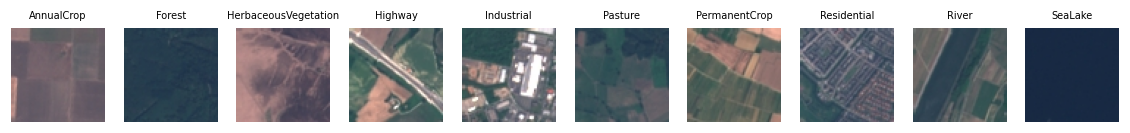

In [4]:
fig, axes = plt.subplots(1, C, figsize=(13, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(X_all[(y_all == c).nonzero()[0, 0]].permute(1, 2, 0)); ax.set_title(CLASSES[c], fontsize=6.5); ax.axis('off')
plt.show()

Las clases están casi balanceadas, pero no del todo. Reportamos la accuracy y también el **F1 macro**, como en Covertype.

La normalización es la de ImageNet para todos los modelos, también para el que se entrena desde cero, y viaja dentro de cada `best.pt`.

In [5]:
MEAN = ResNet18_Weights.IMAGENET1K_V1.transforms().mean
STD = ResNet18_Weights.IMAGENET1K_V1.transforms().std
_m, _s = torch.tensor(MEAN, device=device).view(1, 3, 1, 1), torch.tensor(STD, device=device).view(1, 3, 1, 1)
prep = lambda xb: (xb.to(device).float() / 255 - _m) / _s   # (x/255 − μ)/s con μ, s de ImageNet (notebook 4)

## 2. TODO 1 · Partición y augmentation · 10 min
1. Haz una partición **estratificada** 70/15/15 de los índices (entrenamiento/validación/prueba) con `random_state=0`. Si `TRAIN_SIZE` no es `None`, toma una submuestra de ese tamaño del entrenamiento.
2. Escribe `augment(xb)`: recibe un lote normalizado $N \times 3 \times 64 \times 64$ y devuelve uno del mismo tamaño. Elige transformaciones que **no cambien la clase de una imagen satelital**. Piensa en el *Tu turno* 3 del notebook 3: lo que estaba mal en CIFAR-10, ¿está mal aquí?

No hay estadísticas que calcular con entrenamiento: la normalización es fija. La fuga que hay que evitar aquí es que una misma imagen quede en dos particiones.

In [6]:
TRAIN_SIZE = None            # en CPU: 5_000
idx_all = np.arange(len(y_all))

# 70% entrenamiento, 30% resto (estratificado)
idx_train, idx_tmp = train_test_split(
    idx_all, train_size=0.70, stratify=y_all, random_state=0
)
# el resto se parte por la mitad: 15% validación, 15% prueba
idx_val, idx_test = train_test_split(
    idx_tmp, train_size=0.50, stratify=y_all[idx_tmp], random_state=0
)

# submuestra opcional del entrenamiento (también estratificada)
if TRAIN_SIZE is not None:
    idx_train, _ = train_test_split(
        idx_train, train_size=TRAIN_SIZE, stratify=y_all[idx_train], random_state=0
    )


def augment(xb):
    """Recibe un lote (N, C, H, W) normalizado y devuelve otro del mismo tamaño.
    Solo volteos y rotaciones de 90°: no cambian la clase de una imagen satelital."""
    xb = xb.clone()                      # no modificar el lote original
    n = xb.shape[0]
    dev = xb.device

    # volteo horizontal al azar (cada imagen decide por su cuenta)
    m = torch.rand(n, device=dev) < 0.5
    xb[m] = xb[m].flip(-1)

    # volteo vertical al azar
    m = torch.rand(n, device=dev) < 0.5
    xb[m] = xb[m].flip(-2)

    # rotación de 0, 90, 180 o 270 grados al azar
    k = torch.randint(0, 4, (n,), device=dev)
    for r in (1, 2, 3):
        m = k == r
        if m.any():
            xb[m] = torch.rot90(xb[m], r, dims=(-2, -1))

    return xb

entrenamiento 18900 · validación 4050 · prueba 4050


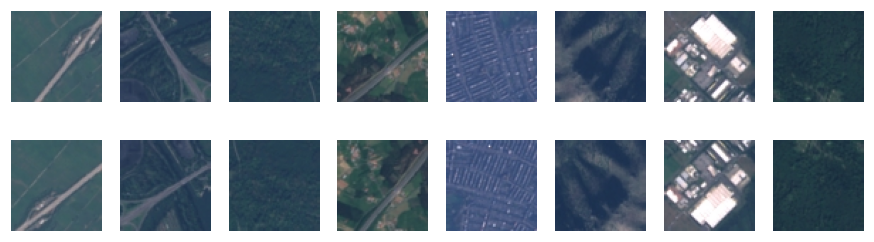

In [7]:
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
props = lambda idx: np.bincount(y_all[idx], minlength=C) / len(idx)
assert np.abs(props(idx_val) - props(idx_test)).max() < 0.01, 'Esperaba una partición estratificada.'
xb = prep(X_all[idx_train[:16]])
xa = augment(xb)
assert xa.shape == xb.shape, 'augment debe devolver un lote del mismo tamaño.'
assert not torch.allclose(xa, xb), 'augment no cambió nada.'
X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]
print('entrenamiento', len(y_train), '· validación', len(y_val), '· prueba', len(y_test))

show = lambda t: (t.cpu() * _s.cpu()[0] + _m.cpu()[0]).clamp(0, 1).permute(1, 2, 0)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for k in range(8):
    axes[0, k].imshow(show(xb[k])); axes[1, k].imshow(show(xa[k]))
for ax in axes.flat: ax.axis('off')
plt.show()

## 3. El loop y MLflow (listo)
`train_epoch` es el loop del notebook 3 con *scheduler* y la norma del gradiente. `run` hace lo mismo que en el integrador de la sesión 02:

- registra en **MLflow** los parámetros, las curvas por época, la pérdida inicial y la norma del gradiente;
- aplica **early stopping** sobre `val_loss`;
- guarda `best.pt` con los pesos **y** todo lo necesario para predecir: el nombre del constructor del modelo, la normalización y el contrato.

`before_epoch` permite, por ejemplo, congelar BatchNorm en cada época (notebook 4, sección 4).

In [8]:
loss_fn = nn.CrossEntropyLoss()  # L_i = −log softmax(f_θ(x_i))_{y_i}; recibe logits
BATCH = 128

def train_epoch(model, opt, scheduler=None, before_epoch=None):
    model.train()
    if before_epoch is not None:
        before_epoch(model)  # p. ej. freeze_bn (notebook 4, sección 4)
    perm = torch.randperm(len(y_train))
    total, norms = 0.0, []
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        # J_𝓑(θ) sobre el lote aumentado: tu augment del TODO 1, solo en entrenamiento (notebook 3, sección 3)
        loss = loss_fn(model(augment(prep(X_train[b]))), y_train[b].to(device))
        opt.zero_grad(); loss.backward()  # g_t = ∇_θ J_𝓑
        # ‖g_t‖ sin recortar (sesión 02, notebook 2, sección 6)
        norms.append(nn.utils.clip_grad_norm_(model.parameters(), float('inf')).item())
        opt.step()
        if scheduler is not None:
            scheduler.step()  # η_t = s(t) · η_0 en cada grupo (notebook 4, sección 4)
        total += loss.item() * len(b)
    return total / len(perm), float(np.mean(norms))

@torch.no_grad()
def evaluate(model, X, y, chunk=512):
    model.eval()  # Dropout apagado, BatchNorm con promedios móviles
    logits = torch.cat([model(prep(X[i:i + chunk])).float().cpu() for i in range(0, len(X), chunk)])
    pred = logits.argmax(1)
    return {'loss': loss_fn(logits, y).item(), 'acc': (pred == y).float().mean().item(),
            'macro_f1': f1_score(y, pred, average='macro', zero_division=0)}, pred.numpy()

In [9]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
EXPERIMENT = 'S03-eurosat'
mlflow.set_experiment(EXPERIMENT)

def run(name, build_model, make_opt, params, epochs=8, patience=3, before_epoch=None):
    torch.manual_seed(0)
    model = build_model().to(device)
    opt, scheduler = make_opt(model, epochs * math.ceil(len(y_train) / BATCH))
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**params, 'epochs': epochs, 'patience': patience, 'train_size': len(y_train),
                           'n_params': sum(p.numel() for p in model.parameters()),
                           'n_trainable': sum(p.numel() for p in model.parameters() if p.requires_grad)})
        mlflow.log_dict(data_card, 'data_card.json')
        mlflow.log_metric('init_loss', evaluate(model, X_val, y_val)[0]['loss'])
        best, best_state, bad = {'val_loss': float('inf')}, None, 0
        for epoch in range(epochs):
            t0 = time.time()
            train_loss, grad_norm = train_epoch(model, opt, scheduler, before_epoch)
            va, _ = evaluate(model, X_val, y_val)
            row = {'train_loss': train_loss, 'grad_norm': grad_norm, 'lr': opt.param_groups[-1]['lr'],
                   'val_loss': va['loss'], 'val_acc': va['acc'], 'val_macro_f1': va['macro_f1'], 'epoch_s': time.time() - t0}
            if not math.isfinite(train_loss):
                mlflow.set_tag('status', 'diverged'); print('  diverge: se detiene'); break
            mlflow.log_metrics(row, step=epoch)
            # early stopping: θ* = argmin_t J_val(θ_t) (sesión 02, notebook 3, sección 4)
            if row['val_loss'] < best['val_loss']:
                best, best_state, bad = {**row, 'epoch': epoch}, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
            if bad == patience:
                mlflow.set_tag('early_stopped', epoch); break
        print(f"{name}: mejor época {best.get('epoch')} · val_loss {best['val_loss']:.4f} · "
              f"val_acc {best.get('val_acc', 0):.3f} · F1 macro {best.get('val_macro_f1', 0):.3f}")
        if best_state is not None:
            mlflow.log_metrics({'best_epoch': best['epoch'], 'best_val_loss': best['val_loss'],
                                'best_val_acc': best['val_acc'], 'best_val_macro_f1': best['val_macro_f1']})
            # best.pt lleva todo lo necesario para predecir: constructor, θ*, normalización y contrato
            torch.save({'model': build_model.__name__, 'state_dict': best_state, 'mean': MEAN, 'std': STD,
                        'contract': CONTRACT}, 'best.pt')
            mlflow.log_artifact('best.pt')
    return model

2026/11/02 04:04:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/02 04:04:08 INFO mlflow.store.db.utils: Updating database tables
2026/11/02 04:04:10 INFO mlflow.tracking.fluent: Experiment with name 'S03-eurosat' does not exist. Creating a new experiment.


## 4. Corrida 1 · Línea base: una CNN desde cero (lista)
La red con bloques VGG y BatchNorm del notebook 3, con 32, 64 y 128 canales para imágenes de 64×64, entrenada desde cero con Adam. Antes de correrla, **predice** su accuracy de validación.

In [10]:
# bloques VGG con BatchNorm del notebook 3, secciones 1–2, para entradas de 64×64
def baseline_model():
    def block(c_in, c_out):
        return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, C))

def baseline_opt(model, total_steps):
    return torch.optim.Adam(model.parameters(), lr=1e-3), None

print(f'ln 10 = {math.log(C):.3f}')
run('1-cnn-desde-cero', baseline_model, baseline_opt, {'estrategia': 'desde cero', 'arquitectura': 'VGG-BN 32-64-128', 'optimizador': 'Adam', 'lr': 1e-3});

ln 10 = 2.303
1-cnn-desde-cero: mejor época 7 · val_loss 0.2034 · val_acc 0.926 · F1 macro 0.923


## 5. TODO 2 · Tu modelo · 15 min
Escribe `my_model()`. Debe devolver un modelo para imágenes de 3×64×64 y 10 salidas. Elige y **justifica** una estrategia del notebook 4:

- *linear probe*: ResNet-18 de ImageNet con el backbone congelado (`requires_grad = False`) y una cabeza nueva;
- *fine-tuning*: la misma red con todo entrenable;
- otra que puedas defender con evidencia.

Sigue la regla del notebook 4: los pesos con `ResNet18_Weights.IMAGENET1K_V1` y una capa `fc` nueva de `C` salidas. Las verificaciones de la celda siguiente son las del integrador de la sesión 02.

In [11]:
def my_model():
    # ResNet-18 con pesos preentrenados en ImageNet
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    # cambiamos la última capa: de 1000 clases de ImageNet a 10 de EuroSAT
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model

In [12]:
torch.manual_seed(0)
m = my_model().to(device)
with torch.no_grad():
    m.eval(); init_loss = loss_fn(m(prep(X_val[:512])), y_val[:512].to(device)).item()
print(f'pérdida inicial {init_loss:.3f} (ln 10 = {math.log(C):.3f}) · entrenables {sum(p.numel() for p in m.parameters() if p.requires_grad):,}')
assert init_loss < 3 * math.log(C), 'La pérdida inicial está muy lejos de ln C: revisa la cabeza nueva.'

xb, yb = prep(X_train[:32]), y_train[:32].to(device)
opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-3); m.train()
for _ in range(150):
    loss = loss_fn(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
print(f'sobreajustar 32 ejemplos: pérdida {loss.item():.4f}')
assert loss.item() < 0.1, 'El modelo no sobreajusta un lote: hay un error en el modelo.'

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


pérdida inicial 2.762 (ln 10 = 2.303) · entrenables 11,181,642
sobreajustar 32 ejemplos: pérdida 0.0000


## 6. TODO 3 · Tu optimizador · 10 min
Escribe `my_opt(model, total_steps)` y que devuelva `(optimizador, scheduler)`:

- `torch.optim.AdamW` con **dos grupos de parámetros**: la cabeza `fc` con un $\eta$ mayor y el resto con uno menor (notebook 4, sección 4). Si tu modelo congela el backbone, el grupo del backbone queda vacío o sus parámetros no se mueven, y está bien;
- *warmup* lineal de **1 época** y decaimiento coseno (`warmup_cosine` del notebook 4). Hay `math.ceil(len(y_train) / BATCH)` pasos por época.

Después, en la celda de la corrida, escribe en `params` lo que elegiste y decide si usas `before_epoch=freeze_bn`.

In [13]:
def freeze_bn(model):
    for mod in model.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.eval()

def my_opt(model, total_steps):
    # dos grupos: la cabeza nueva (fc) y todo lo demás (backbone)
    head = list(model.fc.parameters())
    head_ids = {id(p) for p in head}
    resto = [p for p in model.parameters() if id(p) not in head_ids]

    opt = torch.optim.AdamW(
        [
            {'params': resto, 'lr': 1e-4},   # backbone: ajuste fino, paso pequeño
            {'params': head,  'lr': 1e-3},   # fc nueva: aprende desde cero, paso mayor
        ],
        weight_decay=1e-2,
    )

    warmup = math.ceil(len(y_train) / BATCH)   # pasos de 1 época

    def factor(step):
        if step < warmup:                       # subida lineal
            return (step + 1) / warmup
        prog = (step - warmup) / max(1, total_steps - warmup)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))   # bajada coseno

    sched = torch.optim.lr_scheduler.LambdaLR(opt, factor)
    return opt, sched

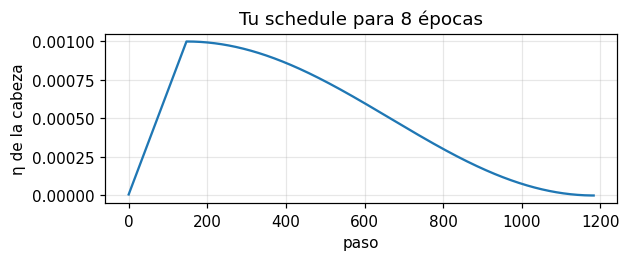

In [14]:
steps_per_epoch = math.ceil(len(y_train) / BATCH)
_m_ = my_model()
_opt, _sched = my_opt(_m_, 8 * steps_per_epoch)
assert isinstance(_opt, torch.optim.AdamW) and len(_opt.param_groups) == 2, 'Esperaba AdamW con dos grupos.'
lr_fc = [g['lr'] for g in _opt.param_groups if any(p is _m_.fc.weight for p in g['params'])]
lr_rest = [g['lr'] for g in _opt.param_groups if not any(p is _m_.fc.weight for p in g['params'])]
assert lr_fc and lr_rest and lr_fc[0] > lr_rest[0], 'La cabeza debe tener un η mayor que el backbone.'
lrs = []
for _ in range(8 * steps_per_epoch):
    lrs.append(_opt.param_groups[-1]['lr']); _opt.step(); _sched.step()
peak = int(np.argmax(lrs))
assert lrs[0] <= 1.5 * max(lrs) / steps_per_epoch and abs(peak - steps_per_epoch) <= 2, 'Esperaba warmup lineal durante la primera época.'
assert lrs[-1] < 0.01 * max(lrs), 'Esperaba que η llegara casi a cero al final.'
plt.figure(figsize=(6, 2)); plt.plot(lrs); plt.xlabel('paso'); plt.ylabel('η de la cabeza'); plt.title('Tu schedule para 8 épocas'); plt.show()

In [15]:
params = {
    'estrategia': 'fine-tuning completo',
    'arquitectura': 'resnet18 ImageNet',
    'optimizador': 'AdamW',
    'lr_backbone': 1e-4,
    'lr_cabeza': 1e-3,
    'weight_decay': 1e-2,
    'schedule': 'warmup 1 época + coseno',
    'augment': 'volteo horizontal y vertical + rotaciones de 90°',
    'freeze_bn': False,
}
run('2-mi-receta', my_model, my_opt, params, before_epoch=None);

2-mi-receta: mejor época 6 · val_loss 0.0747 · val_acc 0.974 · F1 macro 0.973


## 7. Corrida 3 · Cambia una sola cosa · 5 min
Elige **un** cambio a tu receta y córrelo. Si escribes una función de modelo nueva, haz que su nombre termine en `_model` para que el despliegue la encuentre. Algunas opciones: la otra estrategia (probe o fine-tuning), sin augmentation, sin `freeze_bn`, `TRAIN_SIZE = 500`, o subir la imagen a 128×128 dentro del modelo con `nn.Upsample`. Antes de correrlo, escribe en `params` qué esperas que pase.

_Mi cambio y mi predicción:_

In [16]:
class Up128ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.up = nn.Upsample(size=128, mode='bilinear', align_corners=False)
        self.net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.net.fc = nn.Linear(self.net.fc.in_features, 10)

    @property
    def fc(self):                 # my_opt busca model.fc para armar los dos grupos
        return self.net.fc

    def forward(self, x):
        return self.net(self.up(x))

def up128_model():
    return Up128ResNet()

params = {
    'estrategia': 'fine-tuning completo',
    'arquitectura': 'resnet18 ImageNet + Upsample 64→128',
    'optimizador': 'AdamW',
    'lr_backbone': 1e-4,
    'lr_cabeza': 1e-3,
    'weight_decay': 1e-2,
    'schedule': 'warmup 1 	poca + coseno',
    'augment': 'volteos + rotaciones de 90°',
    'freeze_bn': False,
    'cambio': 'subir la imagen a 128x128 dentro del modelo; el resto igual a 2-mi-receta',
    'espero': 'la accuracy de validación sube ~1 a 2 puntos, '
              'pero cada época tarda unas 4 veces más',
}
run('3-mi-receta', up128_model, my_opt, params, before_epoch=None);

3-mi-receta: mejor época 7 · val_loss 0.0468 · val_acc 0.985 · F1 macro 0.985


## 8. Comparar en MLflow (listo)

In [17]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=['attributes.start_time ASC'])
runs = runs.drop_duplicates('tags.mlflow.runName', keep='last').set_index('tags.mlflow.runName')
cols = ['params.n_trainable', 'metrics.init_loss', 'metrics.best_epoch', 'metrics.best_val_loss', 'metrics.best_val_acc', 'metrics.best_val_macro_f1']
runs[cols].round(3)

,params.n_trainable,metrics.init_loss,metrics.best_epoch,metrics.best_val_loss,metrics.best_val_acc,metrics.best_val_macro_f1
tags.mlflow.runName,,,,,,
1-cnn-desde-cero,288746,2.304,7.0,0.203,0.926,0.923
2-mi-receta,11181642,2.716,6.0,0.075,0.974,0.973
3-mi-receta,11181642,2.434,7.0,0.047,0.985,0.985


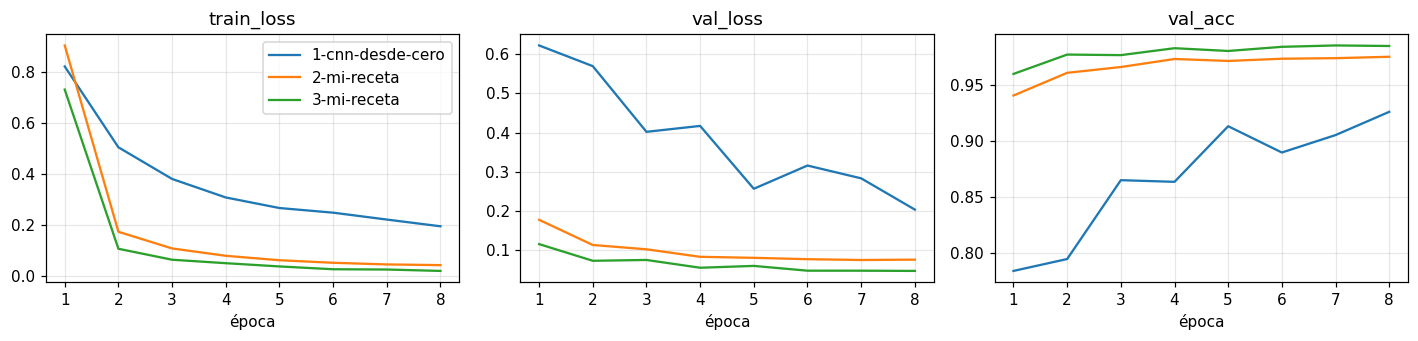

In [18]:
client = mlflow.MlflowClient()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for name, r in runs.iterrows():
    for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
        hist = client.get_metric_history(r.run_id, key)
        ax.plot([m.step + 1 for m in hist], [m.value for m in hist], label=name)
for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
    ax.set(title=key, xlabel='época')
axes[0].legend(); fig.tight_layout(); plt.show()

**Opcional · interfaz web.** En local, ejecuta `mlflow ui --backend-store-uri sqlite:///mlflow.db` y abre http://127.0.0.1:5000. En Kaggle o Colab, descarga `mlflow.db` y `mlruns/` y abre la interfaz en tu máquina.

## 9. Evaluar en prueba una sola vez (listo)
Se elige la corrida por `best_val_loss`, **nunca** por la prueba, y se carga su `best.pt` **desde MLflow**.

In [19]:
chosen = runs.sort_values('metrics.best_val_loss').iloc[0]
print('Corrida elegida:', chosen.name)
ckpt = torch.load(mlflow.artifacts.download_artifacts(run_id=chosen.run_id, artifact_path='best.pt'), map_location='cpu', weights_only=False)
BUILDERS = {f.__name__: f for f in [baseline_model, my_model] + [v for v in globals().values() if callable(v) and getattr(v, '__name__', '').endswith('_model')]}
model = BUILDERS[ckpt['model']](); model.load_state_dict(ckpt['state_dict']); model.to(device).eval()
test_metrics, pred_test = evaluate(model, X_test, y_test)
with mlflow.start_run(run_id=chosen.run_id):
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
print({k: round(v, 4) for k, v in test_metrics.items()})

Corrida elegida: 3-mi-receta


{'loss': 0.0531, 'acc': 0.9825, 'macro_f1': 0.9819}


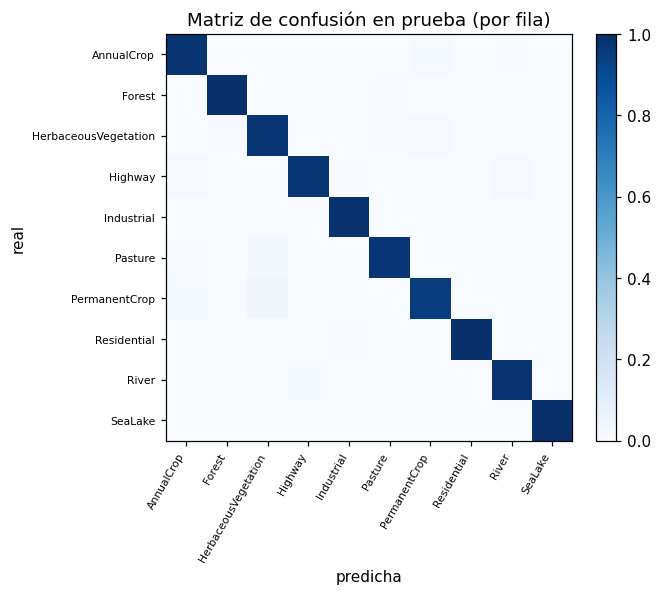

In [20]:
cm = confusion_matrix(y_test, pred_test, normalize='true')
plt.figure(figsize=(5.5, 4.8)); plt.imshow(cm, cmap='Blues', vmin=0, vmax=1); plt.colorbar(fraction=0.046)
plt.xticks(range(C), CLASSES, rotation=60, ha='right', fontsize=7); plt.yticks(range(C), CLASSES, fontsize=7)
plt.xlabel('predicha'); plt.ylabel('real'); plt.title('Matriz de confusión en prueba (por fila)'); plt.grid(False); plt.show()

## 10. TODO 4 · Despliegue: predecir sobre imágenes crudas · 10 min
Escribe `predict_raw(ckpt, images)`. Recibe una **lista de imágenes PIL**, como las que llegarían de un usuario, y devuelve un `DataFrame` con `clase` (el nombre) y `confianza`. Usa solo lo que trae `ckpt`:

1. `validate_image(img, ckpt['contract'])` para cada imagen, y apilar;
2. normalizar con `ckpt['mean']` y `ckpt['std']`;
3. reconstruir el modelo con `BUILDERS[ckpt['model']]()`, cargar los pesos y ponerlo en `eval()`;
4. aplicar softmax y elegir la clase.

In [21]:
@torch.no_grad()
def predict_raw(ckpt, images):
    # 1. Contrato: solo se aceptan imágenes RGB de 64x64
    for im in images:
        if im.mode != 'RGB':
            raise ValueError(f'Se esperaba RGB, llegó {im.mode}')
        if im.size != (64, 64):
            raise ValueError(f'Se esperaba 64x64, llegó {im.size}')

    # 2. Reconstruir el modelo y cargar los pesos entrenados
    model = BUILDERS[ckpt['model']]()
    model.load_state_dict(ckpt['state_dict'])
    model.eval()

    # 3. Mismo preprocesamiento que en entrenamiento
    mean = torch.tensor(ckpt['mean']).view(1, 3, 1, 1)
    std = torch.tensor(ckpt['std']).view(1, 3, 1, 1)
    x = torch.stack([transforms.ToTensor()(im) for im in images])
    x = (x - mean) / std

    # 4. Predicción
    prob = torch.softmax(model(x), dim=1)
    conf, idx = prob.max(dim=1)
    return pd.DataFrame({
        'clase': [CLASSES[i] for i in idx.tolist()],
        'confianza': conf.tolist(),
    })

In [22]:
to_pil = transforms.ToPILImage()
raw_test = [to_pil(x) for x in X_test]                          # imágenes crudas de prueba, como PIL

out = predict_raw(ckpt, raw_test)
agree = (out['clase'].map(CLASSES.index).to_numpy() == pred_test).mean()
print(f'1. Consistencia con la evaluación de prueba: {agree:.2%}')
assert agree > 0.999, 'El artefacto no reproduce las predicciones: ¿falta eval() o la normalización?'

for bad in [raw_test[0].convert('L'), raw_test[0].resize((32, 32))]:
    try:
        predict_raw(ckpt, [bad]); raise AssertionError('Una imagen inválida debió ser rechazada.')
    except ValueError as e:
        print('2. Contrato: imagen rechazada →', e)

pd.concat([pd.DataFrame({'real': [CLASSES[i] for i in y_test[:1000]]}), out.head(1000)], axis=1).to_csv('predicciones.csv', index=False)
print('3. predicciones.csv escrito'); out.head()

1. Consistencia con la evaluación de prueba: 100.00%
2. Contrato: imagen rechazada → Se esperaba RGB, llegó L
2. Contrato: imagen rechazada → Se esperaba 64x64, llegó (32, 32)
3. predicciones.csv escrito


,clase,confianza
0,Pasture,0.999997
1,Residential,0.999986
2,AnnualCrop,0.999993
3,HerbaceousVegetation,0.999866
4,HerbaceousVegetation,0.999557


## 11. Preguntas
1. ¿Se cumplió tu predicción para la línea base? ¿Qué número del registro de MLflow lo muestra?
2. ¿Ayudó ImageNet con imágenes satelitales? Compara la línea base con tu receta en `best_val_acc` **y** en `n_trainable`.
3. ¿Qué transformaciones pusiste en `augment` y por qué no cambian la clase en EuroSAT? ¿Cuál de ellas estaría mal en CIFAR-10?
4. Mira la matriz de confusión: ¿qué pares de clases se confunden más? ¿Te parece razonable viendo las imágenes?
5. ¿Qué pasaría en producción si alguien enviara imágenes de 128×128 de otro satélite? ¿Qué hace hoy `predict_raw` y qué debería hacer?

_Respuestas:_

**1. ¿Se cumplió mi predicción para la línea base?**

Esperaba que una red pequeña entrenada desde cero, con solo 8 épocas, se quedara alrededor del 85–90 % de acierto. Le fue mejor de lo que pensaba: llegó a una accuracy de validación de **92.6 %** (`best_val_acc` = 0.926) y un F1 macro de 0.923. Lo muestra el registro de MLflow de la corrida `1-cnn-desde-cero`.

Otros dos números ayudan a entenderla. Empezó con un error de 2.304 (`init_loss`), que es casi exactamente ln 10 = 2.303: al principio el modelo "adivina" entre las 10 clases por igual, como debe ser. Y su mejor resultado fue en la última época (`best_epoch` = 7), con una curva de validación que todavía subía y bajaba bastante. O sea, seguía aprendiendo: con más épocas probablemente habría mejorado.

**2. ¿Ayudó ImageNet con imágenes satelitales?**

Sí, y bastante. Aunque las fotos de ImageNet (perros, carros, objetos) no se parecen a imágenes tomadas desde el espacio, partir de esa red ya entrenada mejoró todo:

- **Accuracy de validación:** 92.6 % desde cero → **97.4 %** con mi receta (ResNet-18 de ImageNet, ajustada completa) → **98.5 %** con la corrida 3 (la misma receta, agrandando la imagen a 128×128). En prueba, la corrida elegida obtuvo 98.25 % de acierto y F1 macro 0.982.
- **Error de validación (`val_loss`):** bajó de 0.203 a 0.075 y luego a 0.047.
- **Velocidad:** en la primera época el modelo preentrenado ya acertaba ~94 %, mientras que la red desde cero apenas iba en ~78 %.

En `n_trainable` (cuántos números ajusta el modelo), la diferencia es enorme: la red desde cero tiene **288 746** parámetros y la ResNet-18 tiene **11 181 642**, unas 39 veces más. Sin embargo, el tamaño no lo explica todo. Una red grande entrenada desde cero, con tan pocos datos y tan pocas épocas, normalmente aprende mal. Lo que ayudó es que la ResNet-18 ya sabía reconocer cosas básicas como bordes, texturas, manchas de color y patrones repetidos, y eso también sirve para distinguir un bosque de un cultivo o de una zona residencial.

Ojo: esta comparación mezcla dos cosas, el preentrenamiento y una red más grande. Para separarlas, haría una corrida extra con la misma ResNet-18 pero sin los pesos de ImageNet (`weights=None`).

**3. ¿Qué transformaciones puse en `augment` y por qué no cambian la clase?**

Usé tres transformaciones al azar: **volteo horizontal**, **volteo vertical** y **rotaciones de 0°, 90°, 180° o 270°**.

No cambian la clase porque una imagen satelital se toma mirando hacia abajo, desde arriba: no existe un "arriba" ni un "abajo" en la foto. Un río sigue siendo un río si lo giras, y un bosque visto al revés sigue siendo un bosque. Así, el modelo aprende que lo importante es la textura y la forma, no hacia dónde apuntan. Además, no cambié los colores, porque en estas imágenes el color es información clave (el agua es azul oscura, la vegetación verde, los cultivos tienen tonos característicos).

En **CIFAR-10** estarían mal el **volteo vertical** y las **rotaciones de 90°**. Esas son fotos normales tomadas desde el suelo, donde la gravedad importa: un barco, un caballo o un carro boca abajo no es una imagen realista, y el modelo aprendería ejemplos que nunca va a ver. El volteo horizontal sí funciona en CIFAR-10, porque un carro mirando a la izquierda o a la derecha sigue siendo un carro.

**4. ¿Qué pares de clases se confunden más? ¿Es razonable?**

En general los errores son muy pocos (98 % de acierto en prueba), así que la diagonal de la matriz domina. Los pequeños errores que se ven están sobre todo entre clases de vegetación:

- **PermanentCrop** (cultivos permanentes, como frutales) confundido con **HerbaceousVegetation** (vegetación baja) y con **AnnualCrop** (cultivos anuales).
- **Pasture** (pastos) confundido con **HerbaceousVegetation**.
- Unos pocos casos de **Highway** (autopista) confundida con **River** (río).

Sí me parece razonable. A 64×64 píxeles, un cultivo, un pasto y un área de vegetación baja se ven casi iguales: manchas verdes y cafés con texturas parecidas, e incluso a una persona le costaría separarlos. La autopista y el río también se parecen desde arriba: ambos son una franja larga y delgada que cruza la imagen. En cambio, clases con un aspecto muy distinto, como SeaLake (agua casi uniforme) o Forest, casi no se confunden.

**5. ¿Qué pasaría si alguien enviara imágenes de 128×128 de otro satélite?**

**Lo que hace hoy `predict_raw`:** las rechaza. Antes de predecir revisa que cada imagen sea RGB y de 64×64; si llega una de 128×128, lanza un error que dice "Se esperaba 64x64". Eso es bueno: es mejor avisar que algo está mal que devolver una predicción sin sentido.

**Lo que debería hacer:**

- **Usar el contrato que viene en el checkpoint** (`ckpt['contract']`) en lugar de tener 64×64 y RGB escritos a mano en la función. Así, si se entrena un modelo nuevo con otro tamaño, la validación se actualiza sola.
- **Dar un mensaje de error claro** que explique qué formato se espera.
- **No arreglarlo solo con un "resize".** Achicar la imagen a 64×64 haría que pase la validación, pero el problema real es que es otro satélite: cada píxel puede representar una distancia distinta en el suelo (Sentinel-2 usa ~10 m por píxel) y los colores pueden verse diferentes por el sensor. El modelo nunca vio esas imágenes y podría equivocarse con mucha confianza, sin que nadie lo note.
- Si de verdad se necesita usar ese satélite: conseguir algunas imágenes etiquetadas de él, revisar cómo le va al modelo y, si hace falta, reentrenarlo o ajustarlo con esos datos. Mientras tanto, vale la pena registrar la confianza de las predicciones y vigilar si empieza a bajar, porque es una señal de que los datos que llegan ya no se parecen a los del entrenamiento.

**Si quieres ir más allá:** busca con Optuna (sesión 02, notebook 5) el $\eta$ del backbone y de la cabeza; o prueba el ViT-B/16 preentrenado del notebook 5 como backbone, subiendo las imágenes a 224×224.